In [1]:
import pandas as pd
import time
from selenium import webdriver
from webdriver_manager.chrome import ChromeDriverManager
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
import matplotlib.pyplot as plt
import os
import logging

# Full code

In [2]:
from selenium.webdriver.common.by import By
## Setup chrome options
## chrome_options = Options()
## chrome_options.add_argument("--headless") # Ensure GUI is off
## chrome_options.add_argument("--no-sandbox")

## Silent download of drivers
## logging.getLogger('WDM').setLevel(logging.NOTSET)
## os.environ['WDM_LOG'] = 'False'

# Create service
# webdriver_service = Service(ChromeDriverManager().install())

# Create driver
driver = webdriver.Chrome()

# Go to the characters in books page
page_url = "https://breakingbad.fandom.com/wiki/Category:Breaking_Bad_Characters"
driver.get(page_url)

# Click on 'I Accept'
time.sleep(4)
driver.find_element(By.XPATH, '//button[text()="I Accept"]').click()

# Find Seasons
season_categories = driver.find_elements(By.XPATH, "//div[contains(text(), 'H')]/following::ul[1]//a[@class='category-page__member-link']")[:6]

seasons = []
for category in season_categories:
    season_url = category.get_attribute('href')
    season_name = category.text
    seasons.append({'season_name': season_name, "url": season_url})

In [3]:
seasons

[{'season_name': 'Category:Season 1 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_1_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 2 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_2_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 3 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_3_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 4 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_4_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 5A Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_5A_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 5B Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_5B_Characters_(Breaking_Bad)'}]

In [4]:
import re
character_list = []

for season in seasons:
    # go to season page
    driver.get(season['url'])

    character_elems = driver.find_elements(By.CLASS_NAME, 'category-page__member-link')

    # Extract just "Season X" from longer string
    raw_season_name = season['season_name']
    match = re.search(r'Season \d+', raw_season_name)

    # If it finds a match, use it; otherwise, fall back to the raw name
    clean_season_name = match.group(0) if match else raw_season_name

    for elem in character_elems:
        character_list.append({'season': clean_season_name, 'character': elem.text})

In [32]:
pd.DataFrame(character_list)

,season,character
0,Season 1,List of bit parts in Breaking Bad/Season 1
1,Season 1,Hugo Archilleya
2,Season 1,Badger
3,Season 1,Dr. Belknap
4,Season 1,Ben
...,...,...
373,Season 5,Jack Welker
374,Season 5,Holly White
375,Season 5,Skyler White
376,Season 5,Walter White


## Number of characters per season

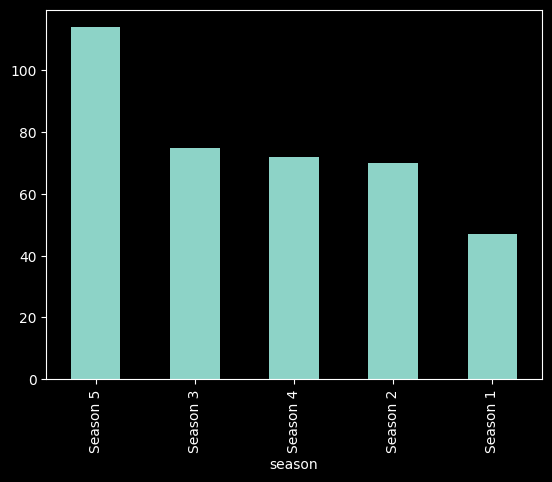

In [33]:
character_df = pd.DataFrame(character_list)

character_df['season'].value_counts().plot(kind="bar")
plt.show()